# Aerosol album: where each particle goes (draft)

Drafts of the particle paths for the four tracks. Particles are seeded where the aerosol is (weighted by AOD) and carried by that species' own wind, GEOS-FP mass flux over column mass, every 3 hours, RK2 with 15-minute steps, linear in time. Nothing is added to the flow.

Section 6 writes the paths the globe draws (`data/aerosol/tracks/paths/`), 100 particles a track (issue #63). No score uses them yet.

In [1]:
import glob, numpy as np, matplotlib.pyplot as plt, matplotlib.colors as mc
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.collections import LineCollection
RAW = "/private/tmp/claude-502/-Users-nell-Projects-nasa-blue-vinyl/69e92539-e9ad-43d2-831b-2febb10b344e/scratchpad/raw"
R = 6371e3
SP = ["dust", "sulfate", "sea_salt", "smoke"]
COLOR = {"sea_salt": "#408cff", "dust": "#ff59bf", "smoke": "#ff731a", "sulfate": "#4cff59"}
files = sorted(glob.glob(RAW + "/*.npz")); NT = len(files); names = [f[-17:-4] for f in files]
D = [np.load(f) for f in files]
AOD = np.stack([d["aod"] for d in D]); M = np.stack([d["mass"] for d in D])
FU = np.stack([d["fu"] for d in D]); FV = np.stack([d["fv"] for d in D])
WU = np.where(M > 1e-9, FU / np.maximum(M, 1e-9), 0).clip(-60, 60)   # m/s, per species
WV = np.where(M > 1e-9, FV / np.maximum(M, 1e-9), 0).clip(-60, 60)
LAT0, DLAT, LON0, DLON = -89.625, 1.0, -179.53, 1.25
LATS = LAT0 + DLAT * np.arange(180); LONS = LON0 + DLON * np.arange(288)
print(NT, "steps", names[0], "to", names[-1])

112 steps 20250811_0130 to 20250824_2230


In [2]:
def samp(F, t, lat, lon):
    i0 = np.clip(np.floor(t).astype(int), 0, NT - 2); f = np.clip(t - i0, 0, 1)
    y = np.clip((lat - LAT0) / DLAT, 0, 178.999); y0 = np.floor(y).astype(int); fy = y - y0
    x = ((lon - LON0) % 360) / DLON; x0 = np.floor(x).astype(int) % 288; x1 = (x0 + 1) % 288; fx = x - np.floor(x)
    g = lambda i: F[i, y0, x0] * (1 - fx) * (1 - fy) + F[i, y0, x1] * fx * (1 - fy) + F[i, y0 + 1, x0] * (1 - fx) * fy + F[i, y0 + 1, x1] * fx * fy
    return g(i0) * (1 - f) + g(i0 + 1) * f

# Eddies. The model's wind is 1 degree and 3-hour means, so the swirls smaller than that are missing from it.
# They are added back as a kinematic-simulation field: a sum of random waves (a divergence-free flow) that turns
# with time, the same for every particle of a wave. The mean drift stays the model's wind.
EDDY_SPEED = 5                 # m/s, rms speed of the added eddies
EDDY_MODES = 8
EDDY_WAVELENGTH_KM = (300, 1000)
EDDY_PERIOD_DAYS = (1, 3)

def make_eddies(seed, lon_ref):
    rng = np.random.default_rng(seed); n = EDDY_MODES
    th = rng.uniform(0, 2 * np.pi, n); k = 2 * np.pi / (rng.uniform(*EDDY_WAVELENGTH_KM, n) * 1e3)
    om = rng.choice([-1, 1], n) * 2 * np.pi / (rng.uniform(*EDDY_PERIOD_DAYS, n) * 86400); ph = rng.uniform(0, 2 * np.pi, n)
    S = EDDY_SPEED / np.sqrt(n / 2)
    def vel(sec, lat, lon):
        x = np.radians((lon - lon_ref + 180) % 360 - 180) * R * np.cos(np.radians(np.clip(lat, -85, 85))); y = np.radians(lat) * R
        c = S * np.cos(k[:, None] * np.cos(th)[:, None] * x + k[:, None] * np.sin(th)[:, None] * y - om[:, None] * sec + ph[:, None])
        return -(np.sin(th)[:, None] * c).sum(0), (np.cos(th)[:, None] * c).sum(0)
    return vel

def advect(sp, lat, lon, t0, steps, sub=12, eddy=None):
    # returns the path every 3 hours (la, lo) and every 30 minutes (fla, flo, for drawing loops smoothly)
    lat = np.array(lat, float); lon = np.array(lon, float); Uf, Vf = WU[:, sp], WV[:, sp]
    out = [(lat.copy(), lon.copy())]; fine = [(lat.copy(), lon.copy())]; dt = 3 * 3600 / sub; t = float(t0)
    mv = lambda u, v, la, lo, h: (la + np.degrees(v * h / R), lo + np.degrees(u * h / (R * np.cos(np.radians(np.clip(la, -85, 85))))))
    ed = lambda tt, la, lo: eddy((tt - t0) * 3 * 3600, la, lo) if eddy else (0, 0)
    for _ in range(steps):
        for j in range(sub):
            if t >= NT - 1.001: break
            e1 = ed(t, lat, lon); la2, lo2 = mv(samp(Uf, t, lat, lon) + e1[0], samp(Vf, t, lat, lon) + e1[1], lat, lon, dt / 2)
            e2 = ed(t + .5 / sub, la2, lo2)
            lat, lon = mv(samp(Uf, t + .5 / sub, la2, lo2) + e2[0], samp(Vf, t + .5 / sub, la2, lo2) + e2[1], lat, lon, dt)
            lon = (lon + 180) % 360 - 180; t += 1 / sub
            if j % 2 == 1: fine.append((lat.copy(), lon.copy()))
        out.append((lat.copy(), lon.copy()))
    return np.array([o[0] for o in out]), np.array([o[1] for o in out]), np.array([o[0] for o in fine]), np.array([o[1] for o in fine])

def hav(la1, lo1, la2, lo2):
    p = np.radians; a = np.sin(p(la2 - la1) / 2) ** 2 + np.cos(p(la1)) * np.cos(p(la2)) * np.sin(p(lo2 - lo1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

def seeds(sp, t, la0, lo0, rad, n=60, seed=1):
    rng = np.random.default_rng(seed); la, lo = np.meshgrid(LATS, LONS, indexing="ij")
    w = np.where(hav(la0, lo0, la, lo) < rad, np.maximum(AOD[t, sp] - 0.012, 0), 0)
    if w.sum() == 0: return None
    i = rng.choice(w.size, n, p=(w / w.sum()).ravel())
    return la.ravel()[i] + rng.uniform(-.5, .5, n), lo.ravel()[i] + rng.uniform(-.6, .6, n)

def rel(lon, cl): return (lon - cl + 180) % 360 - 180   # longitude seen from the map's centre

def draw(ax, sp, t_bg, la, lo, cl, ext, title, src=None, eye=None):
    pc = ccrs.PlateCarree(central_longitude=cl)
    ax.set_extent([ext[0] - cl, ext[1] - cl, ext[2], ext[3]], crs=pc)
    lon_r = rel(LONS, cl); o = np.argsort(lon_r)
    ax.pcolormesh(lon_r[o], LATS, AOD[t_bg, sp][:, o], transform=pc, cmap="magma_r", norm=mc.LogNorm(0.02, 1.5), shading="nearest", alpha=.85)
    ax.add_feature(cfeature.COASTLINE.with_scale("110m"), lw=.6); ax.gridlines(draw_labels=False, lw=.3, alpha=.4)
    lr = np.unwrap(np.radians(rel(lo, cl)), axis=0); lr = np.degrees(lr)
    for i in range(la.shape[1]):
        pts = np.c_[lr[:, i], la[:, i]]; seg = np.stack([pts[:-1], pts[1:]], 1)
        lc = LineCollection(seg, cmap="viridis", transform=pc, lw=1.1, alpha=.9); lc.set_array(np.arange(len(seg))); ax.add_collection(lc)
    ax.scatter(lr[0], la[0], s=6, c="white", ec="k", lw=.3, transform=pc, zorder=5)
    ax.scatter(lr[-1], la[-1], s=8, c="k", transform=pc, zorder=5)
    if src: ax.plot(rel(src[1], cl), src[0], "*", c="w", mec="k", ms=14, transform=pc, zorder=6)
    if eye is not None: ax.plot(rel(eye[1], cl), eye[0], "-", c="w", lw=2, transform=pc, zorder=4)
    ax.set_title(title, fontsize=10)

def summary(sp, t, la0, lo0, rad, days=(1, 3, 5, 7)):
    s = seeds(sp, t, la0, lo0, rad); la, lo, _, _ = advect(sp, *s, t, max(days) * 8); r = {}
    for d in days:
        k = d * 8
        if t + k >= NT: break
        ins = np.mean(samp(AOD[:, sp], t + k, la[k], lo[k]) > 0.05)
        r[d] = (np.median(hav(la[0], lo[0], la[k], lo[k])), np.percentile(hav(la[0], lo[0], la[k], lo[k]), 90), ins)
    return r

## How the paths are made

Each track has a source, a radius, and release times. Every 12 hours a wave of 250 candidate particles is placed inside the radius, more of them where the aerosol is thicker (AOD-weighted), and each one is carried by its own species' wind. Their drift is the model's wind. The model's wind is 1° and 3-hour means, so the swirls smaller than that are missing; they are added back as eddies (a sum of 8 random waves, 300-1000 km, turning in 1-3 days, 5 m/s rms, `EDDY_*` in the first code cell), the same eddy field for all particles of a wave. The eddies are ours, not data: they make a particle loop; the mean drift is the model's. Any of them is a particle the wind and eddies could carry. From these we keep, in each wave, the 4 that travel far (net distance above the median of all candidates that stay in the plume) and wind (path length over net distance), ranked together; a particle that leaves the plume (AOD under 0.05 for more than 30% of the time) is dropped. The grey lines are all the candidates. Erin's source follows the eye (NHC best track). Nothing is steered by hand: a particle that goes nowhere, or turns back, is what the wind did.

In [3]:
import csv
rows = list(csv.DictReader(open("/Users/nell/Projects/nasa/blue-vinyl/.claude/worktrees/feat-63/data/aerosol/tracks/erin.csv")))
elat = np.array([float(r["view_lat"]) for r in rows]); elon = np.array([float(r["view_lon"]) for r in rows])
T = lambda day, hour=0: int(round(((day - 11) * 24 + hour - 1.5) / 3))   # Aug <day> hh:00 UTC -> step

TRACKS = {
    "Hurricane Erin, sea salt": dict(sp=2, src=lambda t: (elat[t], elon[t]), rad=500, rel=range(T(14), T(21), 4), cand=250, per=4, days=6, cl=-55, ext=(-95, -10, 8, 58)),
    "Sahara, dust":             dict(sp=0, src=lambda t: (18, 2), rad=800, rel=range(T(11), T(16), 4), cand=250, per=4, days=9, cl=-35, ext=(-100, 30, 0, 42)),
    "Southern Africa, smoke":  dict(sp=3, src=lambda t: (-12, 22), rad=800, rel=range(T(11), T(18), 4), cand=250, per=4, days=8, cl=0, ext=(-20, 60, -40, 10)),
    "Spain fires, smoke":       dict(sp=3, src=lambda t: (42, -6), rad=600, rel=range(T(11), T(18), 4), cand=250, per=4, days=8, cl=10, ext=(-40, 70, 25, 72)),
}
SULFATE = {
    "Kilauea, sulfate":        dict(sp=1, src=lambda t: (19.4, -155.3), rad=300, rel=range(T(11), T(18), 4), cand=250, per=4, days=6, cl=180, ext=(130, 250, 0, 50)),
    "Eastern China, sulfate":  dict(sp=1, src=lambda t: (33, 118), rad=600, rel=range(T(11), T(18), 4), cand=250, per=4, days=6, cl=160, ext=(90, 230, 5, 60)),
    "Etna, sulfate":           dict(sp=1, src=lambda t: (37.75, 15), rad=300, rel=range(T(13), T(19), 4), cand=250, per=4, days=6, cl=20, ext=(-20, 60, 20, 60)),
}

def run(c):
    # every particle the wind could carry from the source (cand per wave), then the ones that travel far and wind about
    cands = []
    for t in c["rel"]:
        if t + c["days"] * 8 >= NT: continue
        la0, lo0 = c["src"](t); s = seeds(c["sp"], t, la0, lo0, c["rad"], n=c["cand"], seed=t)
        if s is None: continue
        la, lo, fla, flo = advect(c["sp"], *s, t, c["days"] * 8, eddy=make_eddies(t, lo0)); k = la.shape[0]
        net = hav(la[0], lo[0], la[-1], lo[-1]); path = sum(hav(la[i], lo[i], la[i + 1], lo[i + 1]) for i in range(k - 1))
        ins = np.mean([samp(AOD[:, c["sp"]], t + i, la[i], lo[i]) > 0.05 for i in range(k)], axis=0)
        cands.append(dict(t=t, la=la, lo=lo, fla=fla, flo=flo, net=net, tort=path / np.maximum(net, 1), ins=ins))
    if not cands: return [], cands
    ok = np.concatenate([x["ins"] >= 0.7 for x in cands])
    if not ok.any(): return [], cands
    far = np.median(np.concatenate([x["net"] for x in cands])[ok])
    waves = []
    for x in cands:
        e = np.where((x["ins"] >= 0.7) & (x["net"] >= far))[0]
        score = np.argsort(np.argsort(x["net"][e])) + np.argsort(np.argsort(np.minimum(x["tort"][e], 3)))   # far and winding
        e = e[np.argsort(-score)][:c["per"]]
        if len(e): waves.append((x["t"], x["la"][:, e], x["lo"][:, e], x["fla"][:, e], x["flo"][:, e]))
    return waves, cands

def plot_track(name, c, snap=(1, 3, 5)):
    waves, cands = run(c); sp, cl, ext = c["sp"], c["cl"], c["ext"]; pc = ccrs.PlateCarree(central_longitude=cl)
    if not waves: print(name, ": no particles could be seeded (the aerosol there is at the model's floor)"); return waves
    fig = plt.figure(figsize=(17, 6.4)); gs = fig.add_gridspec(1, 2, width_ratios=[1.7, 1])
    ax = fig.add_subplot(gs[0], projection=pc); ax.set_extent([ext[0] - cl, ext[1] - cl, ext[2], ext[3]], crs=pc)
    mid = waves[len(waves) // 2][0]; lon_r = rel(LONS, cl); o = np.argsort(lon_r)
    ax.pcolormesh(lon_r[o], LATS, AOD[min(mid + 16, NT - 1), sp][:, o], transform=pc, cmap="Greys", norm=mc.LogNorm(0.02, 1.5), shading="nearest", alpha=.55)
    ax.add_feature(cfeature.COASTLINE.with_scale("110m"), lw=.6); ax.gridlines(lw=.3, alpha=.4)
    for x in cands:   # every candidate, faint: where the wind could take a particle from this source
        for i in range(0, x["fla"].shape[1], 6):
            ax.plot(np.degrees(np.unwrap(np.radians(rel(x["flo"][:, i], cl)))), x["fla"][:, i], c="#888", lw=.3, alpha=.18, transform=pc)
    cm = plt.get_cmap("plasma"); t_lo, t_hi = waves[0][0], waves[-1][0] + 1
    for t, la, lo, fla, flo in waves:
        lr = np.degrees(np.unwrap(np.radians(rel(flo, cl)), axis=0)); col = cm((t - t_lo) / (t_hi - t_lo))
        for i in range(fla.shape[1]): ax.plot(lr[:, i], fla[:, i], c=col, lw=1.3, alpha=.9, transform=pc)
        ax.scatter(lr[-1], fla[-1], s=9, c=[col], ec="k", lw=.3, transform=pc, zorder=5)
        la0, lo0 = c["src"](t); ax.plot(rel(lo0, cl), la0, "o", c=col, mec="k", ms=7, transform=pc, zorder=6)
    sm = plt.cm.ScalarMappable(cmap=cm); sm.set_array([]); cb = plt.colorbar(sm, ax=ax, shrink=.6, pad=.02); cb.set_ticks([0, 1])
    cb.set_ticklabels([f"Aug {names[t_lo][6:8]} {names[t_lo][9:11]}h", f"Aug {names[t_hi-1][6:8]} {names[t_hi-1][9:11]}h"]); cb.set_label("release time")
    ax.set_title(f"{name}: the {sum(w[1].shape[1] for w in waves)} farthest, most winding of {sum(x['la'].shape[1] for x in cands)} particles, {c['days']} days (grey: all of them)", fontsize=11)
    # one wave, where it is after 0, 1, 3, 5 days, over that day's AOD
    t, la, lo, _, _ = waves[min(1, len(waves) - 1)]; ax2 = fig.add_subplot(gs[1], projection=pc); ax2.set_extent([ext[0] - cl, ext[1] - cl, ext[2], ext[3]], crs=pc)
    ax2.add_feature(cfeature.COASTLINE.with_scale("110m"), lw=.6); ax2.gridlines(lw=.3, alpha=.4)
    ax2.pcolormesh(lon_r[o], LATS, AOD[min(t + snap[-1] * 4, NT - 1), sp][:, o], transform=pc, cmap="Greys", norm=mc.LogNorm(0.02, 1.5), shading="nearest", alpha=.4)
    lr = rel(lo, cl)
    for d, mk, col in zip((0,) + snap, "o^sDP", ["#222", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"]):
        if d * 8 < la.shape[0]: ax2.scatter(lr[d * 8], la[d * 8], s=22, marker=mk, c=col, ec="k", lw=.3, label=f"day {d}", transform=pc, zorder=5)
    ax2.legend(loc="lower left", fontsize=8); ax2.set_title(f"one wave (released Aug {names[t][6:8]} {names[t][9:11]}h): where it is on day 0, {', '.join(map(str, snap))}", fontsize=10)
    plt.tight_layout(); plt.show(); return waves

## 1. Hurricane Erin, sea salt

Source: Erin's eye, 500 km. Releases: Aug 14 to 20, every 12 h.

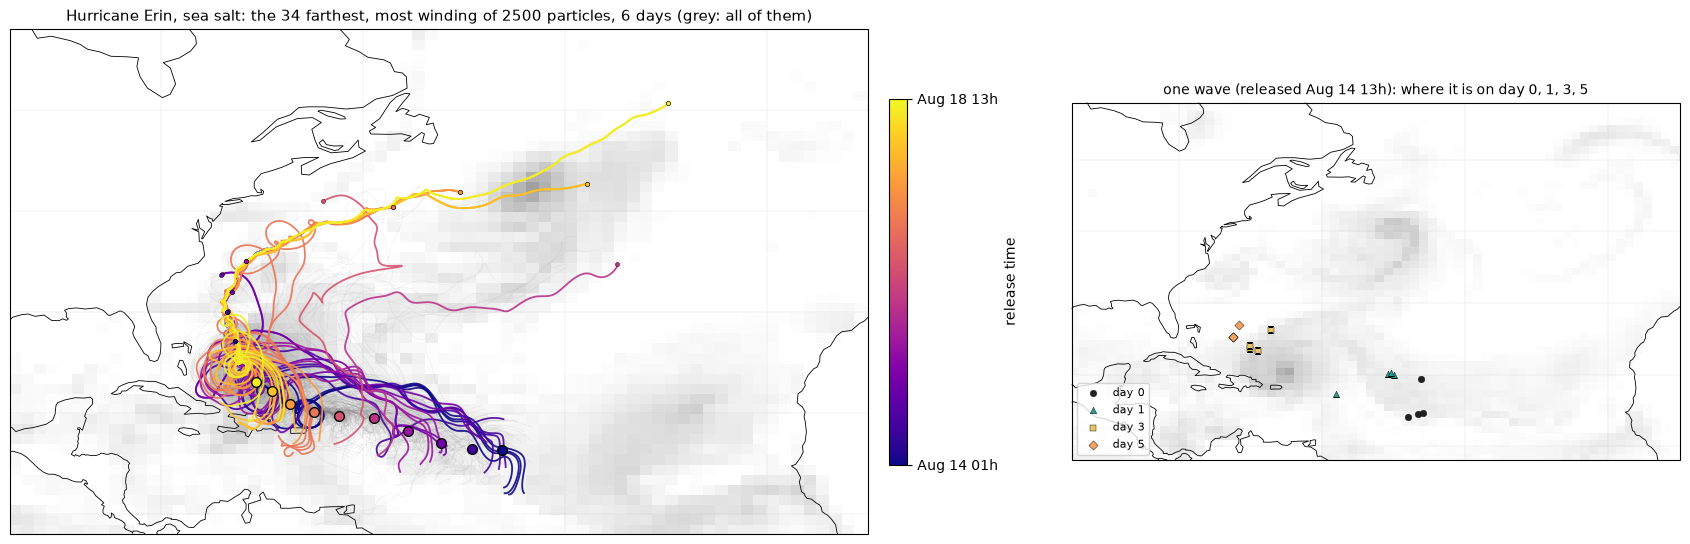

In [4]:
W_erin = plot_track('Hurricane Erin, sea salt', TRACKS['Hurricane Erin, sea salt'])

## 2. Sahara, dust

Source: 18° N, 2° E, 800 km. Releases: Aug 11 to 15, every 12 h.

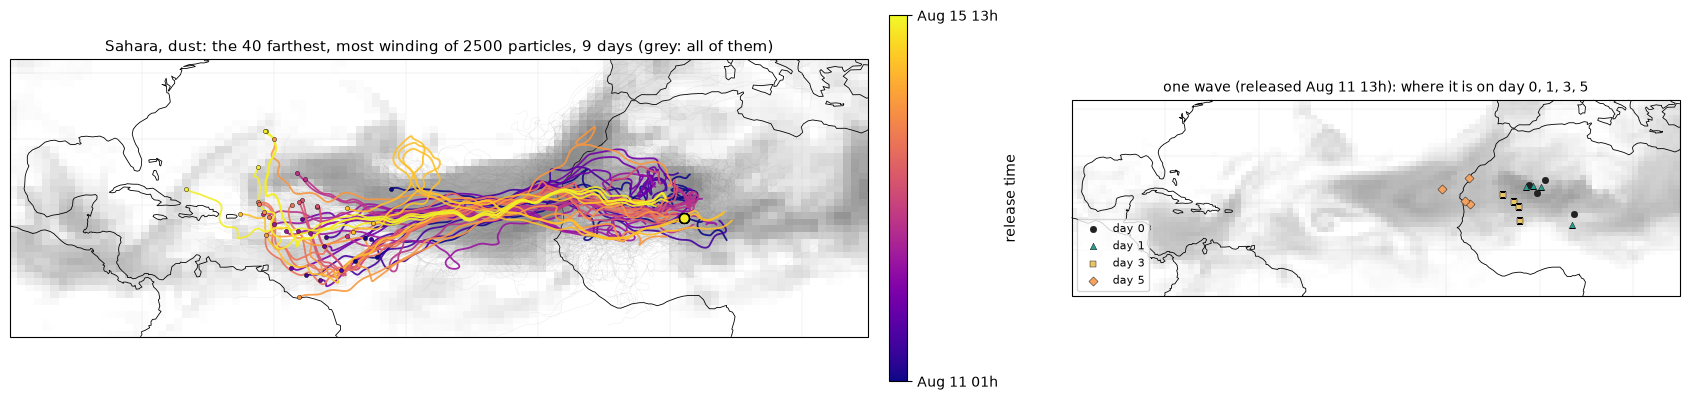

In [5]:
W_sahara = plot_track('Sahara, dust', TRACKS['Sahara, dust'])

## 3. Sulfate: which source can carry a track?

Kilauea against two sources where the model has a sulfate plume.

Kilauea sulfate AOD, max of 5x5 cells at the vent, every 12 h (the model's floor is 0.01):
[0.024 0.02  0.022 0.027 0.021 0.027 0.017 0.018 0.027 0.022 0.028 0.03
 0.026 0.021 0.022 0.023 0.022 0.021 0.018 0.019 0.024 0.018 0.015 0.022
 0.027 0.025 0.021 0.021]


Kilauea, sulfate : no particles could be seeded (the aerosol there is at the model's floor)


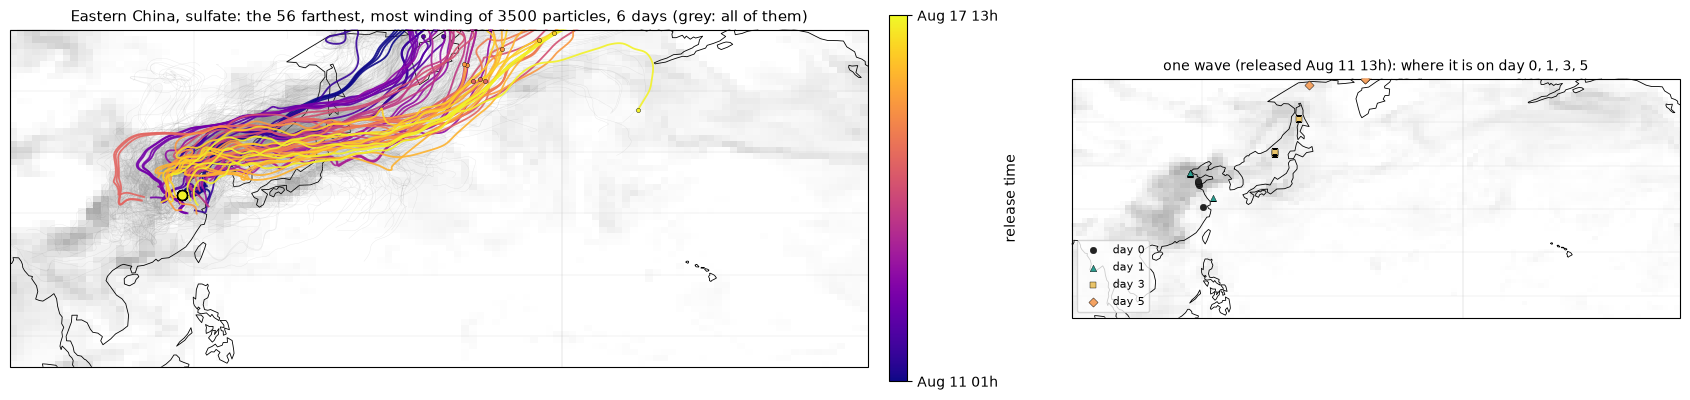

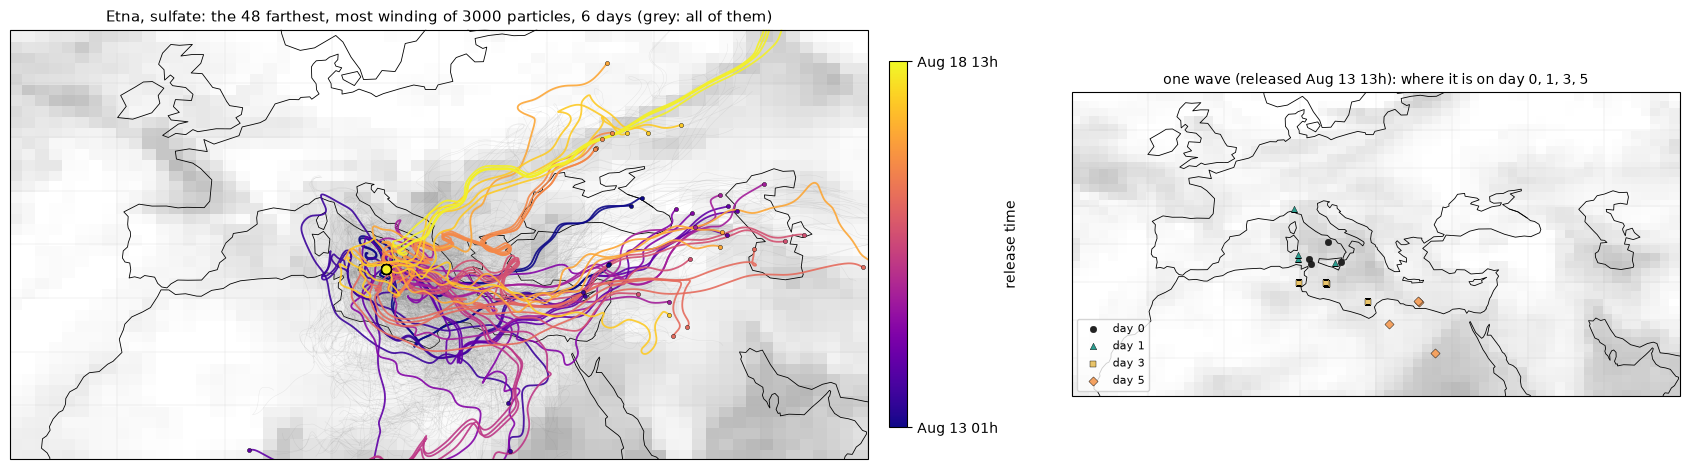

In [6]:
iy = int((19.4 - LAT0) / DLAT); ix = int((-155.3 - LON0) / DLON)
print("Kilauea sulfate AOD, max of 5x5 cells at the vent, every 12 h (the model's floor is 0.01):")
print(np.round([AOD[i, 1, iy-2:iy+3, ix-2:ix+3].max() for i in range(0, NT, 4)], 3))
W_sulfate = {n: plot_track(n, c) for n, c in SULFATE.items()}

## 4. Spain fires, smoke

Source: 42° N, 6° W, 600 km. Releases: Aug 11 to 17, every 12 h.

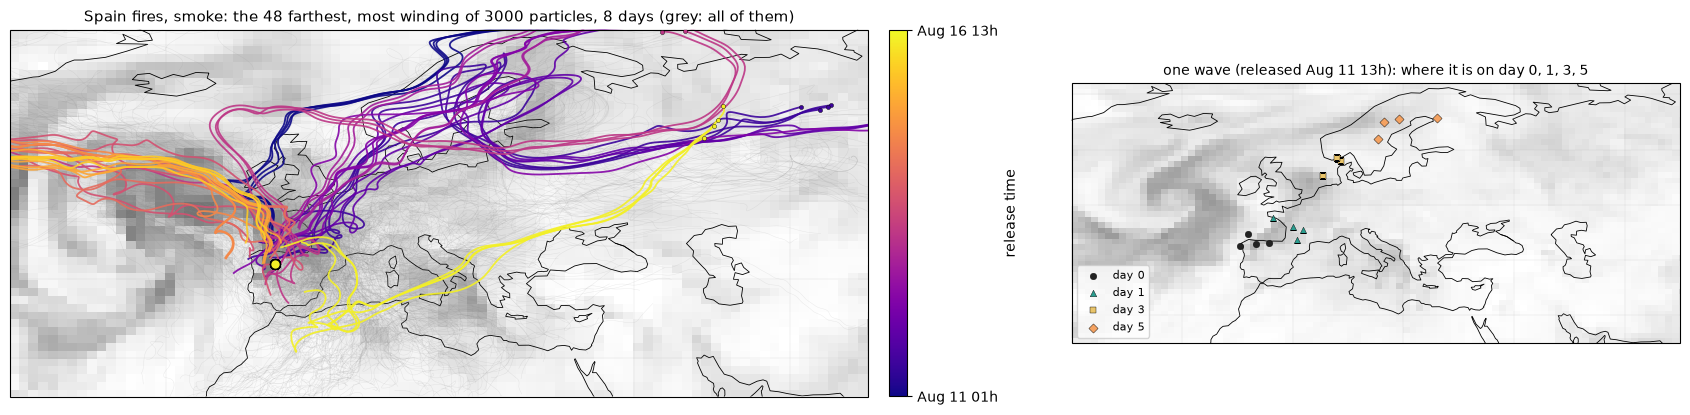

In [7]:
W_spain = plot_track('Spain fires, smoke', TRACKS['Spain fires, smoke'])

## 5. Numbers

Distance from each particle's own start, median and 90th percentile over every wave, and the share still where the species' AOD is above 0.05.

In [8]:
allc = {**TRACKS, **SULFATE}; allw = {"Hurricane Erin, sea salt": W_erin, "Sahara, dust": W_sahara, "Spain fires, smoke": W_spain, **W_sulfate}
print(f"{'':26s}" + "".join(f"{'day ' + str(d):>26s}" for d in (1, 3, 5, 7)) + "     (median / p90 km, in plume)")
for n, W in allw.items():
    line = f"{n:26s}"
    for d in (1, 3, 5, 7):
        k = d * 8; ds = []; ins = []
        for t, la, lo, _, _ in W:
            if k < la.shape[0] and t + k < NT:
                ds += list(hav(la[0], lo[0], la[k], lo[k])); ins += list(samp(AOD[:, allc[n]["sp"]], t + k, la[k], lo[k]) > 0.05)
        line += f"{np.median(ds):>8.0f} /{np.percentile(ds, 90):>6.0f}, {np.mean(ins):>4.0%}  " if ds else " " * 26
    print(line)

                                               day 1                     day 3                     day 5                     day 7     (median / p90 km, in plume)
Hurricane Erin, sea salt       632 /   996, 100%      1783 /  2467, 100%      2686 /  3060,  97%                            
Sahara, dust                   465 /   839,  98%      1593 /  2715, 100%      3012 /  5197, 100%      4665 /  6094,  92%  
Spain fires, smoke             757 /  1189, 100%      1963 /  3024,  98%      3428 /  4607,  81%      4927 /  6429,  75%  
Kilauea, sulfate                                                                                                                  
Eastern China, sulfate         451 /   927,  98%      1873 /  3455,  98%      3981 /  4928,  71%                            
Etna, sulfate                  366 /   780,  94%       963 /  1670,  88%      1954 /  3063,  60%                            


## 6. Paths for the globe

Each track follows one particle type (the last, Etna's sulfate only) and the globe draws 100 of its particles (`PARTICLE_MAX`). They are all released at the track's first step and carried by the wind to its last, so none appears or vanishes on the way. From the 600 candidates seeded at the source on the first step, those that stay in the plume (AOD over 0.05 for 70% of the time or more) and travel farther than the median are eligible. The lead (`hero`) is the eligible particle ranked best by how far it goes and how much it winds, as the waves above; the other 99 are drawn at random from the eligible ones (seeded, so the same every run). The globe circles the lead and follows it with the camera, and the music will follow it. Each file holds, for every particle, the step it is released at (0 here; a step is a row of the track's CSV, 0.25 s in the album) and its position every 3 hours, longitude continuous across the date line.

In [ ]:
import json, os
PARTICLE_MAX = 100
OUT = "../data/aerosol/tracks/paths"
ALBUM_PATHS = {
    "erin": [("seaSalt", TRACKS["Hurricane Erin, sea salt"])],
    "saharan_dust": [("dust", TRACKS["Sahara, dust"])],
    "southern_africa_smoke": [("smoke", TRACKS["Southern Africa, smoke"])],
    "spain_and_etna": [("sulfate", SULFATE["Etna, sulfate"])],
}

def leaders(c, n):
    # n particles released at the track's start and carried to its end, in the plume most of the way and farther than the
    # median. The first is the lead: the best ranked by how far it goes and how much it winds; the rest are drawn at random.
    t0 = 0; la0, lo0 = c["src"](t0); s = seeds(c["sp"], t0, la0, lo0, c["rad"], n=600, seed=t0)
    la, lo, _, _ = advect(c["sp"], *s, t0, NT - 1, eddy=make_eddies(t0, lo0)); k = la.shape[0]
    net = hav(la[0], lo[0], la[-1], lo[-1]); path = sum(hav(la[i], lo[i], la[i + 1], lo[i + 1]) for i in range(k - 1))
    ins = np.mean([samp(AOD[:, c["sp"]], t0 + i, la[i], lo[i]) > 0.05 for i in range(k)], axis=0)
    e = np.where((ins >= 0.7) & (net >= np.median(net[ins >= 0.7])))[0]
    score = np.argsort(np.argsort(net[e])) + np.argsort(np.argsort(np.minimum(path[e] / np.maximum(net[e], 1), 3)))
    lead = e[np.argmax(score)]; rest = np.random.default_rng(t0).permutation(e[e != lead])[:n - 1]
    print(f"   {len(e)} of {la.shape[1]} candidates eligible")
    out = []
    for j in [lead, *rest]:
        lon = np.degrees(np.unwrap(np.radians(lo[:, j])))
        out.append(dict(release=t0, path=np.round(np.c_[la[:, j], lon], 2).tolist()))
    out[0]["hero"] = True
    return out

os.makedirs(OUT, exist_ok=True)
for track, events in ALBUM_PATHS.items():
    particles = [dict(particle=particle, **x) for particle, c in events for x in leaders(c, PARTICLE_MAX // len(events))]
    assert len(particles) <= PARTICLE_MAX, (track, len(particles))
    json.dump(dict(particles=particles), open(f"{OUT}/{track}.json", "w"), separators=(",", ":"))
    print(f"{track:24s} {len(particles):2d} particles, " + ", ".join(f"{p}: {sum(x['particle'] == p for x in particles)}" for p, _ in events))